# 1 · A first model: Jupiter as a single polytrope

**What you will learn:** how to create a planet, give it a pressure–density relation, let PyToF find the hydrostatic equilibrium shape, and read off the gravitational moments $J_{2n}$ — and how to judge whether the numbers can be trusted.

This is the first of five tutorial notebooks:

| notebook | topic |
|---|---|
| **1 · first model** (this one) | create a planet, relax it, read the results, accuracy estimates |
| 2 · plotting | profiles, 2D shape, figure functions, comparing models |
| 3 · your own planet | physical parameters, density profiles, atmospheres, density jumps |
| 4 · beyond the Js | moment of inertia, Love numbers, differential rotation |
| 5 · numerics guide | order, grid size, binning, tolerances, warnings, debugging |

The theory behind PyToF is described in Appendix A of Morf et al. (2024), [doi:10.1051/0004-6361/202450698](https://doi.org/10.1051/0004-6361/202450698).

In [1]:
import sys
import pathlib
import warnings

import numpy as np
import matplotlib.pyplot as plt

# Optional personal matplotlib style: used if a file mpl_config.py exists in a
# folder above this one, silently ignored otherwise.
for parent in pathlib.Path.cwd().resolve().parents[:4]:
    if (parent / "mpl_config.py").exists():
        sys.path.insert(0, str(parent))
        break
try:
    from mpl_config import apply_mpl_opts

    apply_mpl_opts()
except ImportError:
    pass  # plain matplotlib defaults

from PyToF import ToF
from tutorial_utils import Bessel  # literature reference values, see below

`ToF` is the one class you need. Everything — options, results and methods — lives on its instances. Without arguments it describes Jupiter with a 4th order Theory of Figures on 1024 grid points:

In [2]:
X = ToF()
print("Theory of Figures order:", X.opts["order"])
print("grid points N:          ", X.opts["N"])
print("mass [kg]:              ", X.opts["M_phys"])
print("radius [m], kind:       ", X.opts["R_phys"])
print("rotation period [s]:    ", X.opts["Period"])

Theory of Figures order: 4
grid points N:           1024
mass [kg]:               1.8982532431065258e+27
radius [m], kind:        [71492000, 'equatorial']
rotation period [s]:     35729.699778131784


All settings are *options*, passed as keyword arguments (`ToF(order=7)`) and stored in `X.opts`. Misspelled names raise an error instead of being ignored. The complete list with defaults and descriptions is generated from the code, so it is always current:

In [3]:
from IPython.display import Markdown
from PyToF.options import Options

Markdown(Options.describe())

| group | option | default | description |
|---|---|---|---|
| numerics | `N` | 1024 | Number of grid points (level surfaces). |
| numerics | `n_bin` | -1 | Number of bins for the figure functions; -1 or N means no binning, smaller values are faster but less accurate. |
| numerics | `order` | 4 | Theory of Figures order: 4, 7 or 10. |
| numerics | `use_simpson` | True | Use Simpson's rule (otherwise the trapezoid rule) for the pressure and AlgoToF integrals. PyToF falls back to the trapezoid rule on its own if Simpson's rule becomes unstable, see ToF.simpson_in_use. |
| numerics | `dJ_tol` | 1e-10 | Relative tolerance of the gravitational moments. |
| numerics | `drot_tol` | 1e-10 | Relative tolerance of the rotational parameter. |
| numerics | `drho_tol` | 1e-10 | Relative tolerance of the densities. |
| numerics | `max_iter_shape` | 100 | Maximum iterations of relax_to_shape(). |
| numerics | `max_iter_update` | 100 | Maximum iterations of the density update (barotrope, atmosphere) within one step of relax_to_barotrope()/relax_to_density(). |
| numerics | `max_iter_barotrope` | 100 | Maximum iterations of relax_to_barotrope(). |
| numerics | `max_iter_density` | 100 | Maximum iterations of relax_to_density(). |
| output | `verbosity` | 0 | 0: quiet (warnings are always issued); 1: notices; 2: timings and diagnostics; 3: timing of every shape relaxation. |
| output | `debug_plot` | False | Save debug plots at every iteration (very slow). |
| planet | `G` | 6.673848e-11 | Gravitational constant in SI units. |
| planet | `M_phys` | 1.8982532431065258e+27 | Mass of the planet in SI units. |
| planet | `R_phys` | [71492000, 'equatorial'] | Physical radius in SI units and its kind: [value, 'equatorial' | 'mean' | 'polar']. |
| planet | `R_ref` | None | Reference radius for the definition of the Js in SI units; defaults to the value in R_phys. |
| planet | `Period` | np.float64(35729.699778131784) | Rotation period in SI units. |
| planet | `P0` | 0 | Surface pressure in SI units. |
| planet | `alphas` | array of length 12 | Barotropic differential rotation parameters in m^2 s^-2 (typically ~1e5; much smaller values have no visible effect). |
| model | `baro_param_init` | None | Parameters of the barotrope set via set_barotrope(). |
| model | `use_atmosphere` | False | Use an atmospheric model for the outermost densities. |
| model | `atmosphere` | None | Function atmosphere(mean_level_surface, pressure) returning the density of the atmospheric model. |
| model | `atmosphere_until` | None | Pressure in SI units at which the atmospheric model may end earliest. |
| model | `H` | 0.0 | WORK IN PROGRESS |

## The barotrope

PyToF needs one more ingredient: how density depends on pressure, a *barotrope* $\rho = \rho(P)$. We use the simplest model, a polytrope of index 1, $\rho = \sqrt{P/K}$. It is the model of Wisdom & Hubbard (2016, [doi:10.1016/j.icarus.2015.12.030](https://doi.org/10.1016/j.icarus.2015.12.030)), which has an essentially exact (Bessel-function) solution that we can compare against. The constant $K$ is irrelevant here, because the density is rescaled in every iteration to reproduce the given mass.

A barotrope is a function `f(P, param)`. The values you put in `baro_param_init` arrive as `param`:

In [4]:
def barotrope(P, K):
    return (P / K) ** 0.5

X.opts["baro_param_init"] = [1]  # K = 1
X.set_barotrope(barotrope)

## Relaxing to equilibrium

`relax_to_barotrope()` alternates between finding the shape for the current densities (Theory of Figures) and updating pressure and densities for the new shape, until nothing changes any more. It returns the number of iterations:

In [5]:
n_iterations = X.relax_to_barotrope()
print("iterations:", n_iterations)

iterations: 17


**Convergence** means that between two iterations the gravitational moments, the densities and the rotational parameter $m = \omega^2 l_\mathrm{max}^3 / (GM)$ all changed by less than a relative tolerance ($\omega = 2\pi/P_\mathrm{rot}$, $l_\mathrm{max}$ the mean radius of the outermost level surface, $M$ the mass):

In [6]:
for name in ("dJ_tol", "drot_tol", "drho_tol"):
    print(f"{name:9s}", X.opts[name])
print("max_iter_barotrope:", X.opts["max_iter_barotrope"])

dJ_tol    1e-10
drot_tol  1e-10
drho_tol  1e-10
max_iter_barotrope: 100


If the iteration limit is reached first, PyToF issues a `ConvergenceWarning` (an ordinary Python warning, see notebook 5 for how to silence or escalate it). `reset()` throws away all results and starts over from the initial state, so we can repeat the calculation with a limit that is too small:

In [7]:
X.opts["max_iter_barotrope"] = n_iterations - 1
X.reset()
X.relax_to_barotrope()  # warns

X.opts["max_iter_barotrope"] = 100  # back to normal

/home/lumo/Code/PyToF_dev/PyToF/FunctionsToF.py:844: ConvergenceWarning: drot = 4e-12 < 1e-10, dJ = 9e-10 > 1e-10, drho = 4e-12 < 1e-10 after max_iter_barotrope = 16 iterations.
  return _relax(


The option `verbosity` controls how chatty PyToF is: 0 is silent (warnings are always shown), 1 adds notices, 2 timings and diagnostics, 3 the timing of every shape calculation.

In [8]:
X.opts["verbosity"] = 2
X.reset()
X.relax_to_barotrope()
X.opts["verbosity"] = 0

Relaxing to barotrope done in 1.08e-01 seconds.


## Reading the results

The gravitational moments are in `X.Js`. By convention `X.Js[0]` is $-1$ (the monopole) and `X.Js[n]` is $J_{2n}$. The ratio of the equatorial to the mean radius, which defines the oblateness, is in `X.R_eq_to_R_m`.

We compare with the Bessel solution of Wisdom & Hubbard (2016), stored in `Bessel` ($R_\mathrm{eq}/R_\mathrm{m}$, $J_2$, $J_4$, …, $J_{20}$) in the file `accuracy/references.py`:

In [9]:
print(f"{'':12s}{'PyToF':>14s}{'W&H 2016':>14s}{'rel. diff.':>12s}")
print(f"{'Req/Rm':12s}{X.R_eq_to_R_m:14.6f}{Bessel[0]:14.6f}{abs(X.R_eq_to_R_m / Bessel[0] - 1):12.1e}")
for n in range(1, 5):
    print(f"{'J_' + str(2 * n):12s}{X.Js[n]:14.6e}{Bessel[n]:14.6e}{abs(X.Js[n] / Bessel[n] - 1):12.1e}")

                     PyToF      W&H 2016  rel. diff.
Req/Rm            1.022476      1.022875     3.9e-04
J_2           1.398844e-02  1.398851e-02     5.1e-06
J_4          -5.319627e-04 -5.318281e-04     2.5e-04
J_6           2.985996e-05  3.011832e-05     8.6e-03
J_8          -2.336280e-06 -2.132116e-06     9.6e-02


$J_2$ agrees to $5\times10^{-6}$, $J_4$ to $3\times10^{-4}$, and the errors grow quickly for the higher moments. This is expected for a 4th order Theory of Figures: the shape expansion is cut after the 4th order terms, which limits the accuracy of $J_6$ and $J_8$ no matter how fine the grid is. The next section shows how to reduce this.

> **A note on $R_\mathrm{eq}/R_\mathrm{m}$.** The ratio differs from the Bessel value by about $4\times10^{-4}$ for all grid sizes and orders, while the $J$s agree. We have not yet established whether this is a different definition of the "mean" radius or a real discrepancy. Do not use this ratio to better than that without checking; see the accuracy notebooks.

## Order and number of layers

Two knobs control the accuracy: the number of grid points `N` (how finely the planet is divided into level surfaces) and the Theory of Figures `order` (4, 7 or 10; how many terms of the shape expansion are kept). Let us look at the error of $J_2$, $J_4$, $J_6$ and $J_8$ for several of each. The small helper `jupiter()` from `tutorial_utils.py` builds the model above in one line:

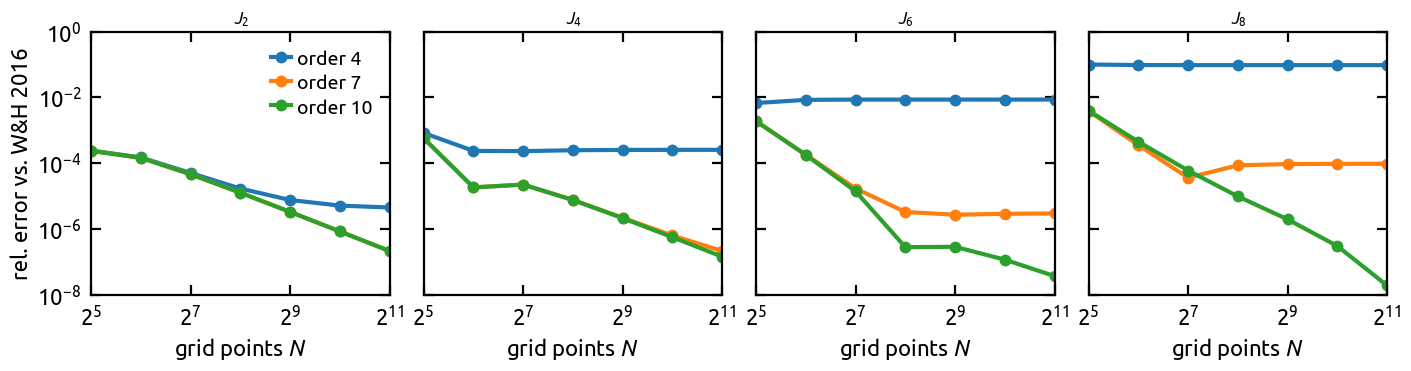

In [10]:
from tutorial_utils import jupiter

Ns = [2**k for k in range(5, 12)]
orders = [4, 7, 10]

fig, axs = plt.subplots(1, 4, figsize=(14, 3.6), layout="constrained", sharey=True)
for order in orders:
    errors = np.array([[abs(jupiter(N, order).Js[n] / Bessel[n] - 1) for n in range(1, 5)] for N in Ns])
    for n, ax in enumerate(axs):
        ax.plot(Ns, errors[:, n], "o-", label=f"order {order}")
for n, ax in enumerate(axs, start=1):
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_ylim(1e-8, 1)
    ax.set_xlabel("grid points $N$")
    ax.set_title(f"$J_{{{2 * n}}}$")
axs[0].set_ylabel("rel. error vs. W&H 2016")
axs[0].legend(frameon=False)

Every order has an *error floor* for each moment, which is reached when the grid is fine enough: with 4th order, $J_2$ stops improving at $\sim5\times10^{-6}$, $J_4$ at $\sim3\times10^{-4}$, $J_6$ at $\sim10^{-2}$; with 7th order, $J_6$ stops at $\sim3\times10^{-6}$ and $J_8$ at $\sim10^{-4}$; the 10th order result keeps improving with $N$ in this range. Below the floor the error is set by the grid and falls with $N$ in the same way for all orders. **More grid points do not help once the order limits the accuracy, and a higher order does not help while the grid limits it.** A good procedure: choose the lowest order whose floor is below the accuracy you need for the highest moment you care about, then increase $N$ until the result stops changing. Notebook 5 quantifies this together with the run time.

## Error estimates

From a large grid study (the notebooks in `accuracy/`) PyToF keeps tables of the relative error of every $J_{2n}$ as a function of order, $N$, number of bins and integration rule. `get_Js_errors()` looks up the entry for the current settings and stores it in `X.Js_errors` (same indexing as `X.Js`):

In [11]:
X = jupiter(N=1024, order=10)
X.get_Js_errors()
for n in range(1, 5):
    print(f"J_{2 * n} = {X.Js[n]:.6e} +/- {X.Js_errors[n]:.1e}   (W&H 2016: {Bessel[n]:.6e})")

J_2 = 1.398850e-02 +/- 1.2e-08   (W&H 2016: 1.398851e-02)
J_4 = -5.318278e-04 +/- 3.0e-10   (W&H 2016: -5.318281e-04)
J_6 = 3.011832e-05 +/- 3.5e-12   (W&H 2016: 3.011832e-05)
J_8 = -2.132116e-06 +/- 6.4e-13   (W&H 2016: -2.132116e-06)


These errors are *numerical* errors of the Theory of Figures for a polytrope like this one; they say nothing about how well a model describes a real planet. They are only available for solid-body rotation and an equidistant grid. With differential rotation, `get_Js_errors()` warns and returns nothing useful: the accuracy there is unknown.

## Takeaways

* `ToF(**options)` → `set_barotrope(f)` → `relax_to_barotrope()` → read `X.Js`.
* Convergence is controlled by three relative tolerances and an iteration limit; `reset()` starts over.
* Accuracy has two independent limits, the grid (`N`) and the order; `get_Js_errors()` estimates the combined error.

Next: [2 · plotting](02_plotting.ipynb).